In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [25]:
img = cv2.imread("bird.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
img = cv2.resize(img, (224, 224))
# output_img = np.zeros_like(img, dtype=np.float32)
output_img = img.copy()

#### 1. Applying only the Laplacian (del square operator) Finite differences of Finite Differences

In [27]:
kernel_dim = 3
for i in range(kernel_dim//2, img.shape[0] - kernel_dim):
    for j in range(kernel_dim//2, img.shape[1] - kernel_dim):
        img_slice = img[i:i+kernel_dim, j:j+kernel_dim]

        slice_center_row = img_slice[img_slice.shape[0]//2]
        del_square_i_x = slice_center_row[kernel_dim-1] - 2 * slice_center_row[kernel_dim//2] + slice_center_row[0]

        slice_center_col = img_slice[:, kernel_dim//3]
        del_square_i_y = slice_center_col[kernel_dim-1] - 2 * slice_center_col[kernel_dim//2] + slice_center_col[0]

        output_img[i+kernel_dim//2, j+kernel_dim//2] = del_square_i_x + del_square_i_y

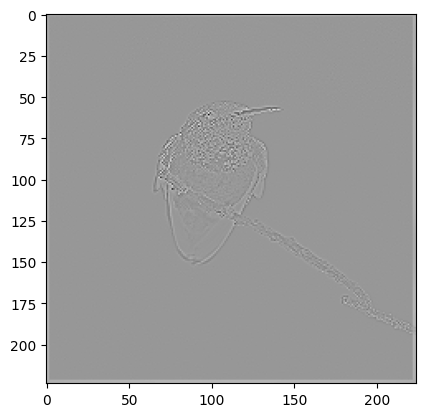

In [30]:
plt.imshow(output_img, cmap="grey")